## Molecular Property Prediction — EDA Capstone

**Goal:** explore seven MoleculeNet-style datasets and prepare reliable modelling recommendations.  
Keep each code cell short (about 5–6 lines), run cells from top to bottom, and place `molecular_property_prediction_datasets.xlsx` beside this notebook.

### Imports and configuration

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
sns.set_theme(style="whitegrid")

In [2]:
candidates = [Path("molecular_property_prediction_datasets.xlsx"), Path("/mnt/data/molecular_property_prediction_datasets.xlsx")]
WORKBOOK_PATH = next((p for p in candidates if p.exists()), None)
if WORKBOOK_PATH is None: raise FileNotFoundError("Place the Excel workbook beside this notebook.")
xls = pd.ExcelFile(WORKBOOK_PATH)
print("Sheets:", xls.sheet_names)

Sheets: ['Overview', 'BBBP', 'ESOL', 'FreeSolv', 'Lipophilicity', 'ClinTox', 'Tox21', 'BACE']


### Load datasets

In [3]:
print(f"Total sheets: {len(xls.sheet_names)}")
sheet_names = [s for s in xls.sheet_names if s.lower() != "overview"]
datasets = {s: pd.read_excel(xls, sheet_name=s) for s in sheet_names}
summary = pd.DataFrame([{"Dataset": n, "Rows": len(d), "Columns": d.shape[1]} for n, d in datasets.items()])
display(summary.sort_values("Rows", ascending=False).reset_index(drop=True))

Total sheets: 8


,Dataset,Rows,Columns
0,Tox21,7831,14
1,Lipophilicity,4200,3
2,BBBP,2050,4
3,BACE,1513,595
4,ClinTox,1484,3
5,ESOL,1128,10
6,FreeSolv,642,4


In [4]:
total_rows = sum(len(df) for df in datasets.values())
print(f"Datasets: {len(datasets)}")
print(f"Total rows across sheets: {total_rows:,}")
print("Note: rows across sheets are not necessarily unique molecules.")

Datasets: 7
Total rows across sheets: 18,848
Note: rows across sheets are not necessarily unique molecules.


### Dataset schemas and sample rows

In [5]:
for name, df in datasets.items():
    print(f"\n{name}: {df.shape[0]:,} rows × {df.shape[1]} columns")
    display(df.head(3))


BBBP: 2,050 rows × 4 columns


,num,name,p_np,smiles
0,1,Propanolol,1,[Cl].CC(C)NCC(O)COc1cccc2ccccc12
1,2,Terbutylchlorambucil,1,C(=O)(OC(C)(C)C)CCCc1ccc(cc1)N(CCCl)CCCl
2,3,40730,1,c12c3c(N4CCN(C)CC4)c(F)cc1c(c(C(O)=O)cn2C(C)CO...



ESOL: 1,128 rows × 10 columns


,Compound ID,ESOL predicted log solubility in mols per litre,Minimum Degree,Molecular Weight,Number of H-Bond Donors,Number of Rings,Number of Rotatable Bonds,Polar Surface Area,measured log solubility in mols per litre,smiles
0,Amigdalin,-0.974,1,457.432,7,3,7,202.32,-0.77,OCC3OC(OCC2OC(OC(C#N)c1ccccc1)C(O)C(O)C2O)C(O)...
1,Fenfuram,-2.885,1,201.225,1,2,2,42.24,-3.30,Cc1occc1C(=O)Nc2ccccc2
2,citral,-2.579,1,152.237,0,0,4,17.07,-2.06,CC(C)=CCCC(C)=CC(=O)



FreeSolv: 642 rows × 4 columns


...

,smiles,FDA_APPROVED,CT_TOX
0,C(=O)[C@H](CCCCNC(=O)OCCOC)NC(=O)OCCOC,1,0
1,[C@@H]1([C@@H]([C@@H]([C@H]([C@@H]([C@@H]1Cl)C...,1,0
2,[C@H]([C@@H]([C@@H](C(=O)[O-])O)O)([C@H](C(=O)...,1,0



Tox21: 7,831 rows × 14 columns


,NR-AR,NR-AR-LBD,NR-AhR,NR-Aromatase,NR-ER,NR-ER-LBD,NR-PPAR-gamma,SR-ARE,SR-ATAD5,SR-HSE,SR-MMP,SR-p53,mol_id,smiles
0,0.0,0.0,1.0,NaN,NaN,0.0,0.0,1.0,0.0,0.0,0.0,0.0,TOX3021,CCOc1ccc2nc(S(N)(=O)=O)sc2c1
1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,NaN,0.0,NaN,0.0,0.0,TOX3020,CCN1C(=O)NC(c2ccccc2)C1=O
2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,NaN,0.0,NaN,NaN,TOX3024,CC[C@]1(O)CC[C@H]2[C@@H]3CCC4=CCCC[C@@H]4[C@H]...



BACE: 1,513 rows × 595 columns


,smiles,CID,Class,Model,pIC50,MW,AlogP,HBA,HBD,RB,...,PEOE6 (PEOE6),PEOE7 (PEOE7),PEOE8 (PEOE8),PEOE9 (PEOE9),PEOE10 (PEOE10),PEOE11 (PEOE11),PEOE12 (PEOE12),PEOE13 (PEOE13),PEOE14 (PEOE14),canvasUID
0,O1CC[C@@H](NC(=O)[C@@H](Cc2cc3cc(ccc3nc2N)-c2c...,BACE_1,1,Train,9.154901,431.56979,4.4014,3,2,5,...,53.205711,78.640335,226.85541,107.43491,37.133846,0.000000,7.980170,0.0,0.000000,1
1,Fc1cc(cc(F)c1)C[C@H](NC(=O)[C@@H](N1CC[C@](NC(...,BACE_2,1,Train,8.853872,657.81073,2.6412,5,4,16,...,73.817162,47.171600,365.67694,174.07675,34.923889,7.980170,24.148668,0.0,24.663788,2
2,S1(=O)(=O)N(c2cc(cc3c2n(cc3CC)CC1)C(=O)N[C@H](...,BACE_3,1,Train,8.698970,591.74091,2.5499,4,3,11,...,70.365707,47.941147,192.40652,255.75255,23.654478,0.230159,15.879790,0.0,24.663788,3


In [6]:
schema_rows = []
for name, df in datasets.items():
    schema_rows.extend([{"Dataset": name, "Column": c, "Dtype": str(df[c].dtype), "Missing": int(df[c].isna().sum())} for c in df.columns])

In [7]:
schema = pd.DataFrame(schema_rows)
display(schema.head(30))
print("Total columns across all sheets:", len(schema))

,Dataset,Column,Dtype,Missing
0,BBBP,num,int64,0
1,BBBP,name,str,0
2,BBBP,p_np,int64,0
3,BBBP,smiles,str,0
4,ESOL,Compound ID,str,0
5,ESOL,ESOL predicted log solubility in mols per litre,float64,0
6,ESOL,Minimum Degree,int64,0
7,ESOL,Molecular Weight,float64,0
8,ESOL,Number of H-Bond Donors,int64,0
9,ESOL,Number of Rings,int64,0


Total columns across all sheets: 633


### Missing values

In [8]:
missing = pd.DataFrame([{"Dataset": n, "Missing cells": int(d.isna().sum().sum()),
    "Missing %": round(d.isna().sum().sum() / d.size * 100, 2),
    "Columns with missing": int(d.isna().any().sum())} for n, d in datasets.items()])
display(missing.sort_values("Missing %", ascending=False))

,Dataset,Missing cells,Missing %,Columns with missing
5,Tox21,16026,14.62,12
1,ESOL,0,0.00,0
0,BBBP,0,0.00,0
2,FreeSolv,0,0.00,0
3,Lipophilicity,0,0.00,0
4,ClinTox,0,0.00,0
6,BACE,0,0.00,0


In [9]:
missing_cols = {n: d.isna().sum().sort_values(ascending=False).loc[lambda x: x > 0]
                for n, d in datasets.items()}
for name, counts in missing_cols.items():
    if not counts.empty:
        print(f"\n{name}:")
        display(counts.to_frame("Missing rows").head(15))


Tox21:


,Missing rows
SR-MMP,2021
NR-Aromatase,2010
SR-ARE,1999
NR-ER,1638
NR-PPAR-gamma,1381
SR-HSE,1364
NR-AhR,1282
NR-AR-LBD,1073
SR-p53,1057
NR-ER-LBD,876


**Interpretation:** Tox21 assay labels may be missing by design. Do not drop an entire molecule just because one assay label is missing; handle missing labels separately for each target.

### Target variables and class imbalance

In [10]:
targets = {"BBBP": "p_np", "ESOL": "measured log solubility in mols per litre",
           "FreeSolv": "expt", "Lipophilicity": "exp", "ClinTox": "CT_TOX",
           "BACE": "Class"}
for name, target in targets.items():
    print(name, "→", target if target in datasets[name].columns else "TARGET COLUMN NOT FOUND")

BBBP → p_np
ESOL → measured log solubility in mols per litre
FreeSolv → expt
Lipophilicity → exp
ClinTox → CT_TOX
BACE → Class


In [11]:
for name in ["BBBP", "ClinTox", "BACE"]:
    target = targets[name]
    if target in datasets[name]:
        counts = datasets[name][target].value_counts(dropna=False).sort_index()
        display(counts.rename("count").to_frame().assign(percent=lambda x: (x["count"] / x["count"].sum() * 100).round(2)))

,count,percent
p_np,,
0,483,23.56
1,1567,76.44


,count,percent
CT_TOX,,
0,1372,92.45
1,112,7.55


,count,percent
Class,,
0,822,54.33
1,691,45.67


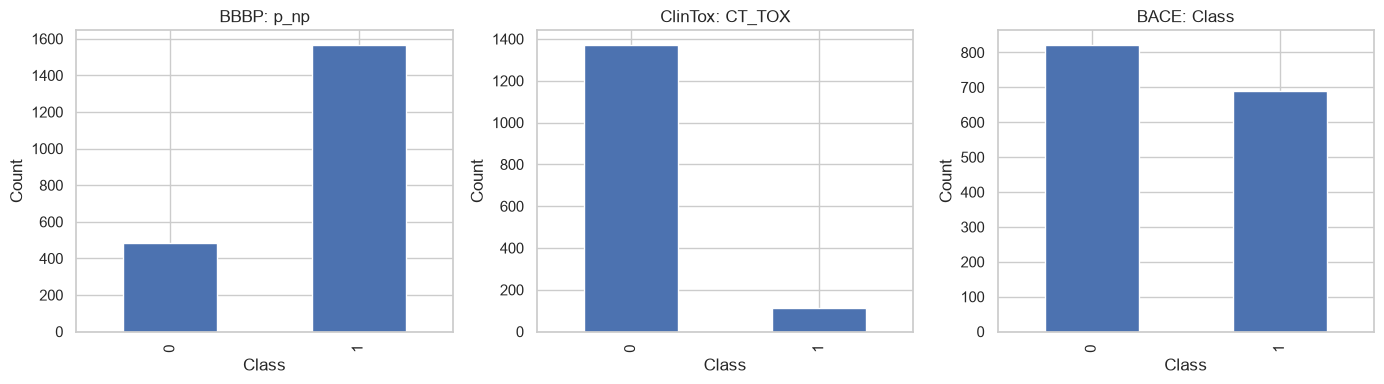

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, name in zip(axes, ["BBBP", "ClinTox", "BACE"]):
    target = targets[name]
    datasets[name][target].value_counts().sort_index().plot(kind="bar", ax=ax)
    ax.set_title(f"{name}: {target}"); ax.set_xlabel("Class"); ax.set_ylabel("Count")
plt.tight_layout()

**Modelling note:** ClinTox is imbalanced. Compare PR-AUC, recall, precision, and F1; accuracy alone can look strong while the rare class is missed.

### Regression target distributions

In [13]:
regression_targets = {"ESOL": "measured log solubility in mols per litre",
                      "FreeSolv": "expt", "Lipophilicity": "exp"}
for name, target in regression_targets.items():
    values = pd.to_numeric(datasets[name][target], errors="coerce").dropna()
    print(f"{name}: n={len(values)}, mean={values.mean():.3f}, std={values.std():.3f}, skew={values.skew():.3f}")

ESOL: n=1128, mean=-3.050, std=2.096, skew=-0.492
FreeSolv: n=642, mean=-3.803, std=3.848, skew=-1.176
Lipophilicity: n=4200, mean=2.186, std=1.203, skew=-0.582


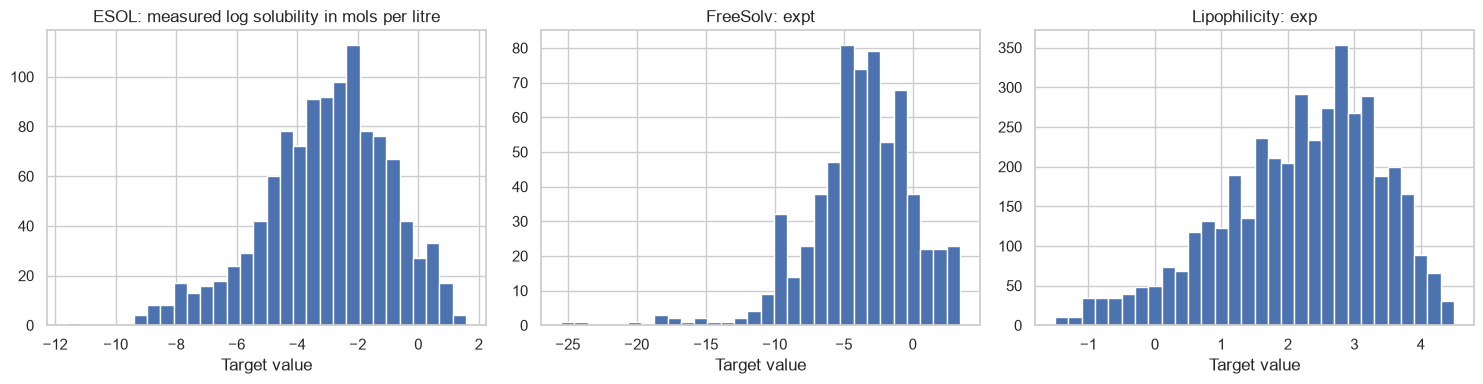

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (name, target) in zip(axes, regression_targets.items()):
    values = pd.to_numeric(datasets[name][target], errors="coerce").dropna()
    ax.hist(values, bins=30, edgecolor="white")
    ax.set_title(f"{name}: {target}"); ax.set_xlabel("Target value")
plt.tight_layout()

In [15]:
for name, target in regression_targets.items():
    values = pd.to_numeric(datasets[name][target], errors="coerce").dropna()
    q1, q3 = values.quantile([0.25, 0.75]); iqr = q3 - q1
    outliers = ((values < q1 - 1.5 * iqr) | (values > q3 + 1.5 * iqr)).sum()
    print(f"{name}: IQR outliers = {outliers} ({outliers / len(values) * 100:.1f}%)")

ESOL: IQR outliers = 17 (1.5%)
FreeSolv: IQR outliers = 15 (2.3%)
Lipophilicity: IQR outliers = 22 (0.5%)


Outliers should be investigated, not automatically deleted: unusual molecular properties may be scientifically valid.

### SMILES and duplicate checks

In [16]:
smiles_cols = {n: next((c for c in d.columns if "smiles" in c.lower()), None) for n, d in datasets.items()}
for name, col in smiles_cols.items():
    if col:
        s = datasets[name][col].dropna()
        print(f"{name}: {len(s):,} non-missing SMILES, {s.nunique():,} unique, {s.duplicated().sum():,} duplicate rows")
    else: print(f"{name}: no SMILES column found")

BBBP: 2,050 non-missing SMILES, 2,050 unique, 0 duplicate rows
ESOL: 1,128 non-missing SMILES, 1,128 unique, 0 duplicate rows
FreeSolv: 642 non-missing SMILES, 642 unique, 0 duplicate rows
Lipophilicity: 4,200 non-missing SMILES, 4,200 unique, 0 duplicate rows
ClinTox: 1,484 non-missing SMILES, 1,484 unique, 0 duplicate rows
Tox21: 7,831 non-missing SMILES, 7,831 unique, 0 duplicate rows
BACE: 1,513 non-missing SMILES, 1,513 unique, 0 duplicate rows


In [17]:
smiles_stats = []
for name, col in smiles_cols.items():
    if col:
        lengths = datasets[name][col].dropna().astype(str).str.len()
        smiles_stats.append({"Dataset": name, "Mean length": lengths.mean(), "Min": lengths.min(), "Max": lengths.max()})
display(pd.DataFrame(smiles_stats).round(2))

,Dataset,Mean length,Min,Max
0,BBBP,51.47,3,400
1,ESOL,22.52,1,98
2,FreeSolv,15.33,1,82
3,Lipophilicity,47.50,11,267
4,ClinTox,59.34,2,339
5,Tox21,35.60,2,342
6,BACE,65.22,17,198


SMILES strings that differ textually can still represent the same molecule. If RDKit is available, canonicalize SMILES before deduplication or scaffold splitting.

### RDKit descriptor availability (optional)

In [18]:
try:
    from rdkit import Chem
    from rdkit.Chem import Descriptors
    RDKIT_AVAILABLE = True
except ImportError:
    RDKIT_AVAILABLE = False; print("RDKit is not installed. Install it with: pip install rdkit")

In [19]:
descriptor_rows = []
if RDKIT_AVAILABLE:
    for name, col in smiles_cols.items():
        if col:
            valid = datasets[name][col].dropna().map(lambda s: Chem.MolFromSmiles(str(s)) is not None)
            descriptor_rows.append({"Dataset": name, "Valid SMILES": int(valid.sum()), "Invalid SMILES": int((~valid).sum())})

[19:03:38] Explicit valence for atom # 1 N, 4, is greater than permitted
[19:03:38] WARNING: not removing hydrogen atom without neighbors
[19:03:38] Explicit valence for atom # 6 N, 4, is greater than permitted
[19:03:39] WARNING: not removing hydrogen atom without neighbors
[19:03:39] WARNING: not removing hydrogen atom without neighbors
[19:03:39] WARNING: not removing hydrogen atom without neighbors
[19:03:39] WARNING: not removing hydrogen atom without neighbors
[19:03:39] WARNING: not removing hydrogen atom without neighbors
[19:03:39] WARNING: not removing hydrogen atom without neighbors
[19:03:39] Explicit valence for atom # 6 N, 4, is greater than permitted
[19:03:39] WARNING: not removing hydrogen atom without neighbors
[19:03:39] WARNING: not removing hydrogen atom without neighbors
[19:03:39] WARNING: not removing hydrogen atom without neighbors
[19:03:39] WARNING: not removing hydrogen atom without neighbors
[19:03:39] Explicit valence for atom # 11 N, 4, is greater than pe

In [20]:
display(pd.DataFrame(descriptor_rows))

,Dataset,Valid SMILES,Invalid SMILES
0,BBBP,2039,11
1,ESOL,1128,0
2,FreeSolv,642,0
3,Lipophilicity,4200,0
4,ClinTox,1480,4
5,Tox21,7823,8
6,BACE,1513,0


In [21]:
def get_descriptors(smiles):
    mol = Chem.MolFromSmiles(str(smiles)) if RDKIT_AVAILABLE and pd.notna(smiles) else None
    if mol is None: return None
    return {"MolWt": Descriptors.MolWt(mol), "LogP": Descriptors.MolLogP(mol),
            "TPSA": Descriptors.TPSA(mol), "HBD": Descriptors.NumHDonors(mol),
            "HBA": Descriptors.NumHAcceptors(mol)}

In [22]:
if RDKIT_AVAILABLE and smiles_cols.get("ESOL"):
    esol_desc = pd.DataFrame(datasets["ESOL"][smiles_cols["ESOL"]].map(get_descriptors).tolist())
    display(esol_desc.describe().T.round(3))
else:
    print("ESOL descriptors skipped; install RDKit and check the SMILES column.")

,count,mean,std,min,25%,50%,75%,max
MolWt,1128.0,203.937,102.738,16.043,121.183,182.179,270.372,780.949
LogP,1128.0,2.448,1.853,-7.571,1.415,2.339,3.402,10.389
TPSA,1128.0,34.873,35.384,0.000,0.000,26.300,55.440,268.680
HBD,1128.0,0.701,1.090,0.000,0.000,0.000,1.000,11.000
HBA,1128.0,2.069,2.109,0.000,0.000,2.000,3.000,16.000


### Leakage and feature-selection checks

In [23]:
for name, df in datasets.items():
    cols = [c for c in df.columns if any(k in c.lower() for k in ["predicted", "prediction", "model", "canvasuid"])]
    print(f"{name}: review these possible leakage/metadata columns: {cols}")

BBBP: review these possible leakage/metadata columns: []
ESOL: review these possible leakage/metadata columns: ['ESOL predicted log solubility in mols per litre']
FreeSolv: review these possible leakage/metadata columns: []
Lipophilicity: review these possible leakage/metadata columns: []
ClinTox: review these possible leakage/metadata columns: []
Tox21: review these possible leakage/metadata columns: []
BACE: review these possible leakage/metadata columns: ['Model', 'canvasUID']


In [24]:
esol_suspects = [c for c in datasets["ESOL"].columns if "predicted" in c.lower()]
print("ESOL predicted columns:", esol_suspects)
print("Exclude precomputed predictions when predicting measured solubility.")

ESOL predicted columns: ['ESOL predicted log solubility in mols per litre']
Exclude precomputed predictions when predicting measured solubility.


For BACE, exclude `Class` and `pIC50` from features when predicting either one, and remove identifier columns such as `CID`, `smiles`, and `Model`. Fit feature selection and scaling only on training data.

### Recommended modelling plan

| Dataset | Task | Models to compare | Metrics |
|---|---|---|---|
| ESOL | Regression | Ridge, Random Forest, Gradient Boosting, SVR | MAE, RMSE, R² |
| BBBP | Binary classification | Logistic Regression, Random Forest, XGBoost/SVM | ROC-AUC, PR-AUC, F1 |
| ClinTox | Imbalanced classification | Class-weighted Logistic Regression, Random Forest, boosting | PR-AUC, recall, F1 |
| Tox21 | Multi-label classification | Per-assay classifiers; optional multi-output approach | Per-assay ROC-AUC / PR-AUC |
| BACE | Classification or regression | Random Forest, gradient boosting, Logistic Regression | ROC-AUC / PR-AUC or MAE / RMSE |

**Best first capstone:** build ESOL regression and BBBP classification pipelines, then extend to ClinTox. Use scaffold-based train/test splits where feasible to estimate generalization to new chemical structures. Report measured results only after running validation and test experiments.

### Final dataset summary

In [25]:
print("EDA completed.")
print(f"Datasets: {len(datasets)} | Total rows across sheets: {sum(len(d) for d in datasets.values()):,}")
display(summary.sort_values("Rows", ascending=False).reset_index(drop=True))

EDA completed.
Datasets: 7 | Total rows across sheets: 18,848


,Dataset,Rows,Columns
0,Tox21,7831,14
1,Lipophilicity,4200,3
2,BBBP,2050,4
3,BACE,1513,595
4,ClinTox,1484,3
5,ESOL,1128,10
6,FreeSolv,642,4
